# Viz comparison: real GeoLife traces against synthetic traces

How the real Beijing traces and the synthetic traces generated outside from a DP artifact behave, side by
side. **Black is always the real data**; the coloured line is the synthetic variant. This notebook lives in
`geolife/eval/` because it needs both: the real points (`geolife/inside/data/points.parquet`) and a stage-2
output (`geolife/outside/synthetic/<variant>_seed<k>/`). The library code is `src/geolife/eval/viz.py`
(panels) and `src/geolife/eval/compare.py` (quantities, moments, distances) - a new statistic is one line
in `compare.QUANTITIES`.

For the **direct lon/lat overlay** the synthetic variant must be generated into the source city:
`PYTHONPATH=src python geolife/outside/generate_synthetic.py --only outings_v2_seed0 --city beijing --n-users 139`.
A teleported variant (other city) is drawn in centred metric frames instead (same scale, km from each
dataset's centroid); the shape panels do not depend on the frame at all.

Both sides go through the **same tokenizer** (`transfer/tokenize/outings.py`, public Beijing places table),
so outing-level gaps are generator gaps, not tokenizer artefacts. Times are local (UTC+8).

In [1]:
import os, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline
warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "geolife").exists())
sys.path.insert(0, str(ROOT / "src"))
from geolife.eval import compare as C
from geolife.eval import viz as V
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)

POINTS = os.environ.get("GEOLIFE_POINTS", str(ROOT / "geolife/inside/data/points.parquet"))
PLACES = os.environ.get("GEOLIFE_PLACES", str(ROOT / "geolife/outside/cache/places_beijing_big.parquet"))
SYN    = os.environ.get("GEOLIFE_SYN",    str(ROOT / "geolife/outside/synthetic/outings_v2_seed0"))
TAG    = os.environ.get("GEOLIFE_COMPARE_TAG", "")   # suffix for the summary table: keeps earlier tables as history
print(POINTS, "\n" + PLACES, "\n" + SYN)

/home/ds/twin/user_nd/git/twin/.claude/worktrees/geolife-aim/src/algorithms/algo_aim/geolife/inside/data/points.parquet 
/home/ds/twin/user_nd/git/twin/.claude/worktrees/geolife-aim/src/algorithms/algo_aim/geolife/outside/cache/places_beijing_big.parquet 
/home/ds/twin/user_nd/git/twin/.claude/worktrees/geolife-aim/src/algorithms/algo_aim/geolife/outside/synthetic/outings_v2_seed0


In [2]:
places = pd.read_parquet(PLACES)
real = C.bundle_from_points_parquet(POINTS, label="real", places=places)       # Beijing core bbox
syn = C.bundle_from_synthetic(SYN, label=Path(SYN).name, places=places)
syns = {syn.label: syn}
for b in (real, syn):
    print(f"{b.label}: {len(b.arrays)} users, {sum(len(a[0]) for a in b.arrays.values()):,} points, "
          f"{len(b.outings)} tokenized users, {sum(len(u.outings) for u in b.outings):,} outings")

real: 179 users, 18,238,686 points, 128 tokenized users, 17,195 outings
outings_v2_seed0: 139 users, 28,046,872 points, 126 tokenized users, 16,961 outings


## 1. Space

Density of all GPS points, the difference of the two normalised densities (orange = synthetic excess,
blue = real excess), the marginal lon/lat histograms with KS, and a few example users' raw traces at the
same scale. *Look for:* does the synthetic mass sit on the same corridors and hubs, and do single users'
traces have the same visual texture (noise, stops, straight transit runs)?

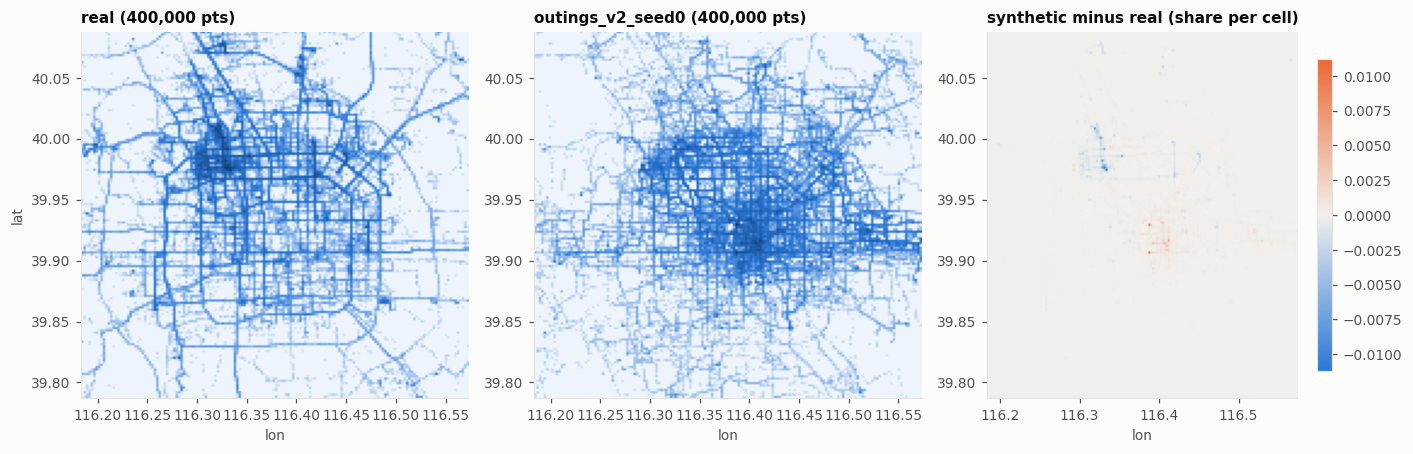

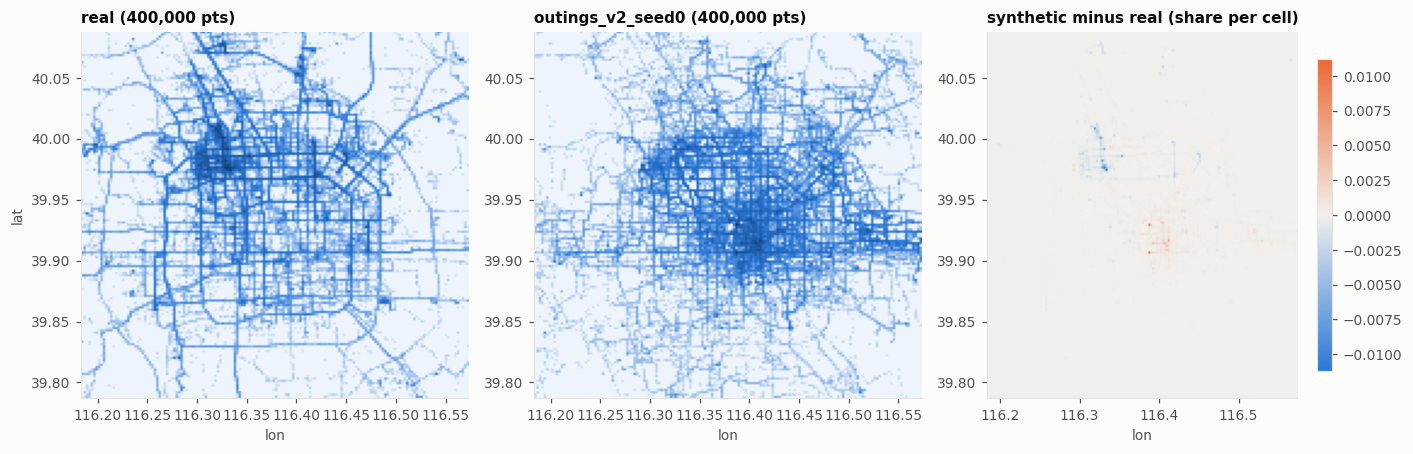

In [3]:
V.density_maps(real, syns)

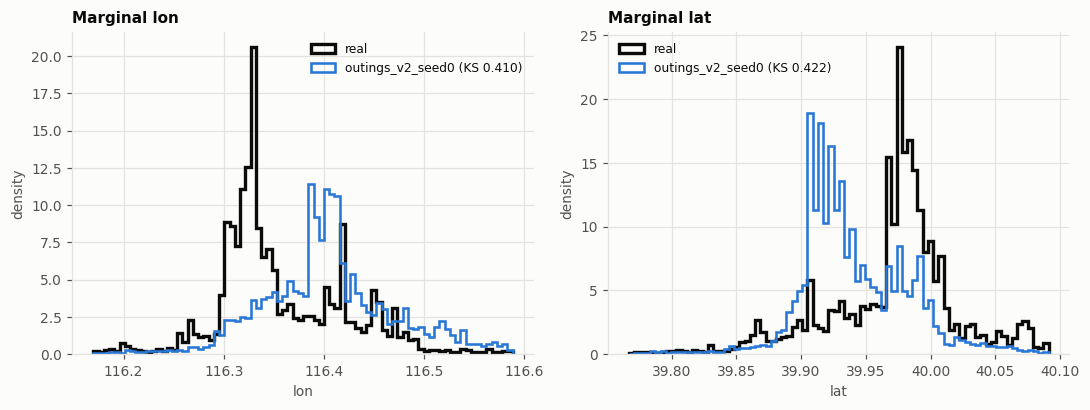

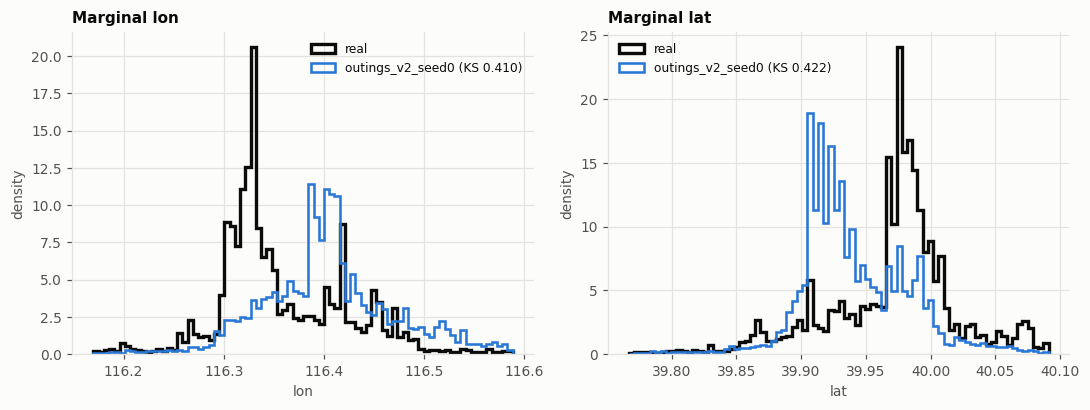

In [4]:
V.marginal_histograms(real, syns)

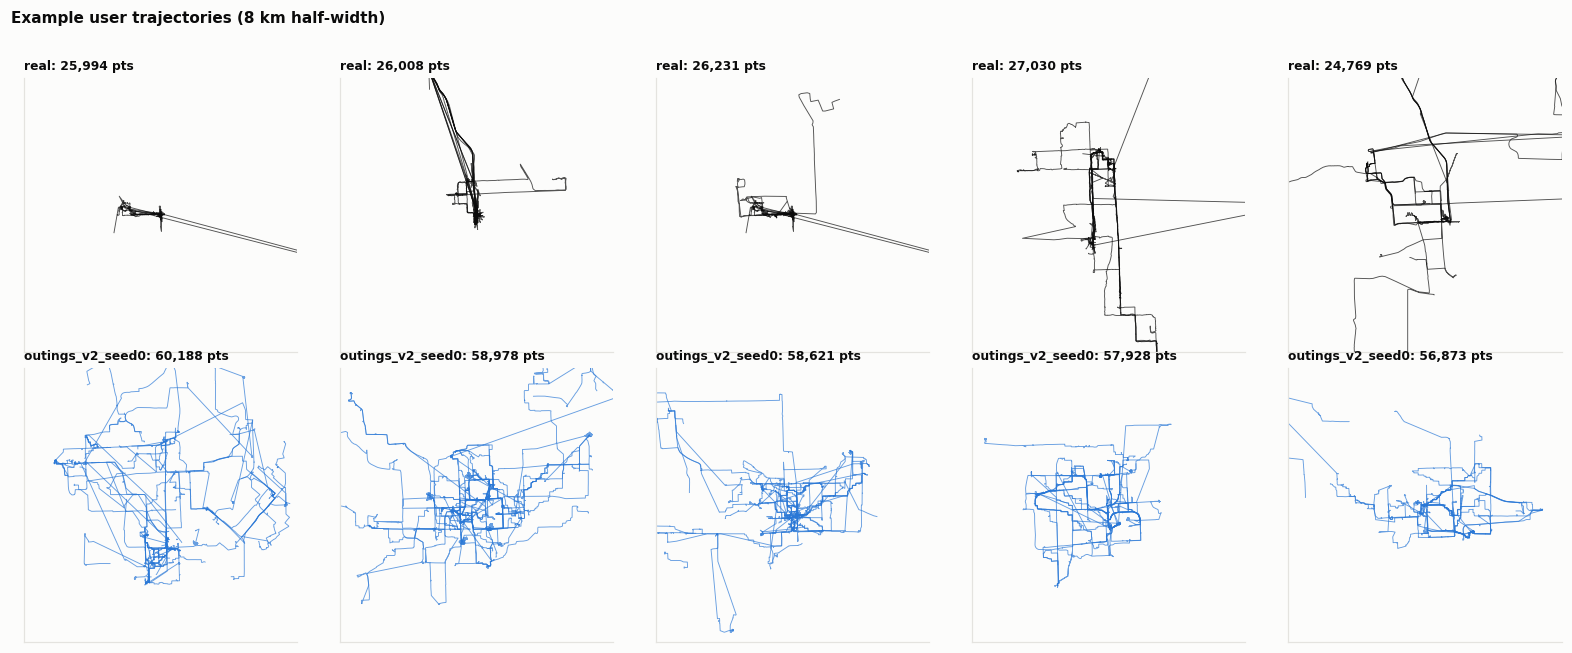

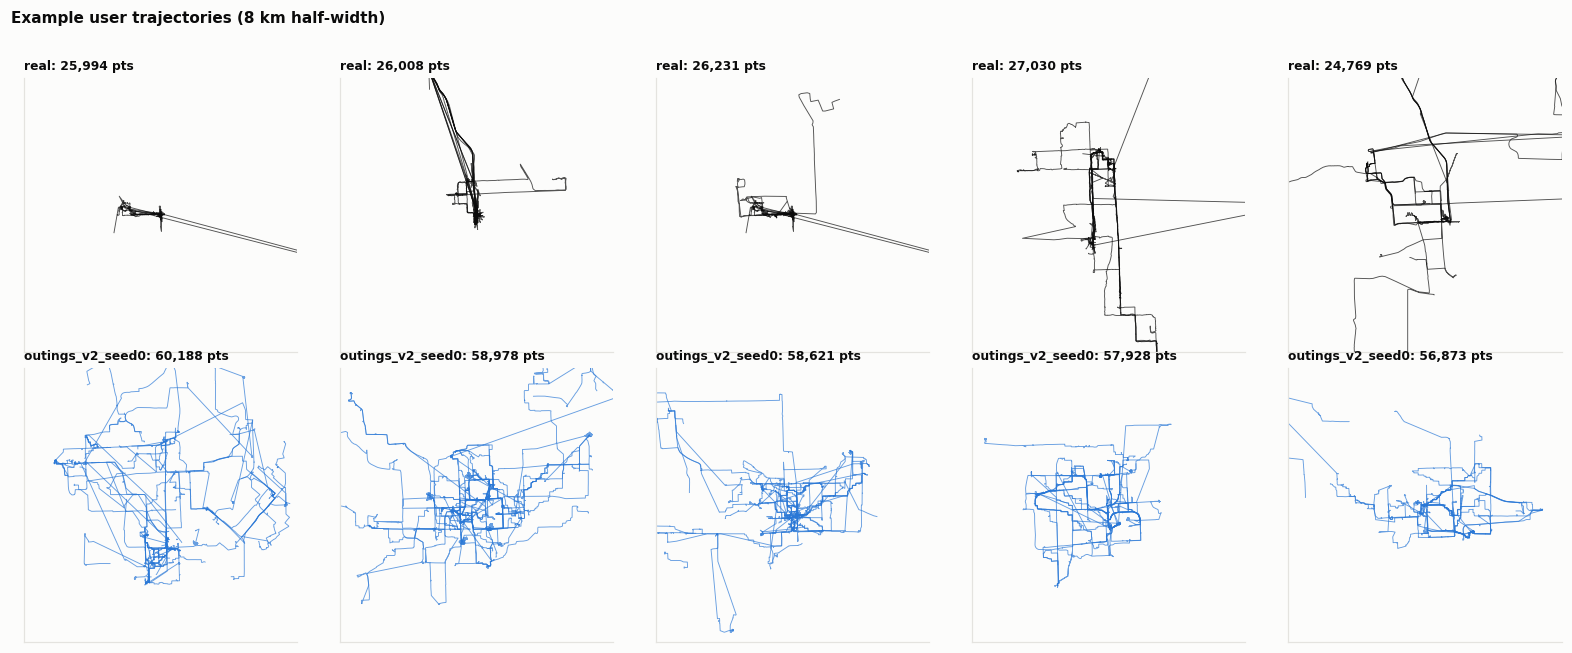

In [5]:
V.example_trajectories(real, syns, n=5)

**What we see (2026-11-03; dt-round synthetic set: artifacts v2e, 28 tables, 139 users, 28.0M
points).** The synthetic points sit on the real road network, but in the wrong part of the city: real
mass centres on Haidian (median lon 116.336, lat 39.977), synthetic mass on the city centre (116.402,
39.931), about 6 km east and 5 km south; marginal KS 0.41 / 0.42. It is not a few heavy users: with
every user weighted equally the KS is 0.46 per axis. The released place tables DO point at Haidian
(`place_users_r6/r7` weighted centre ~39.95-39.96 / 116.35, heaviest cells at 39.977 / 116.341), while
the synthetic mass lands on the centre of the public places table (39.931 / 116.411). So in the source
city the generator places activity by public-map density rather than by the released H3 cells - a
generator issue, not yet traced in the code. Example traces: real users are thin lines with long
straight jumps (signal gaps) inside a small area; synthetic users follow the roads and spread over far
more of the 8 km window (distinct places per user 181 vs 109).

## 2. Moments and shape

ECDF overlays and QQ plots for every numeric quantity: point level (sampling interval, gap length, step
length, speed overall and by mode, heading change, positional jitter at stops), outing level (length,
duration, stops, dwell) and user level (points, outings, active days, distinct places, revisit rate).
*Look for:* bulk agreement in the ECDFs; QQ points on the diagonal (above = synthetic heavier tail).

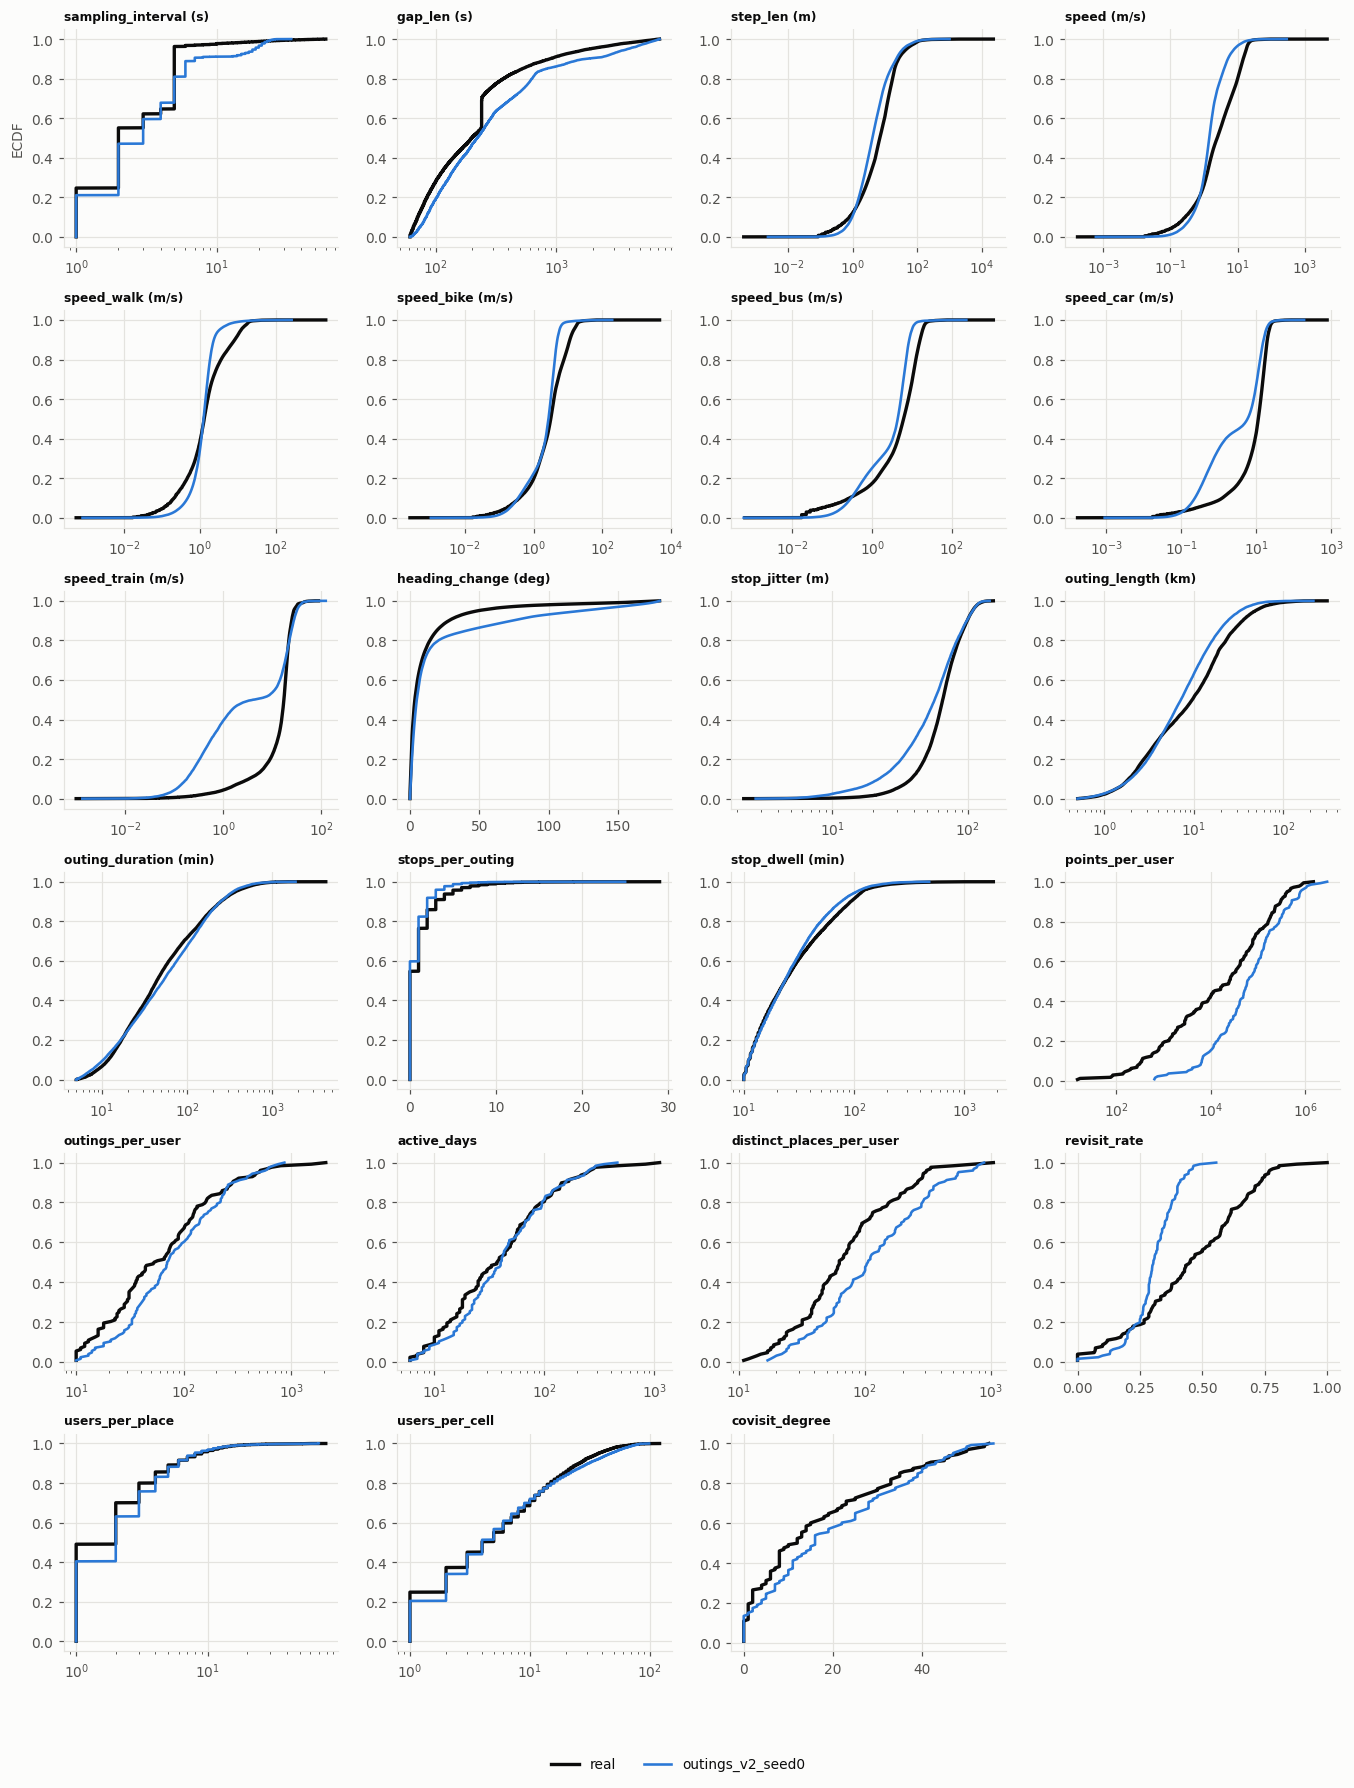

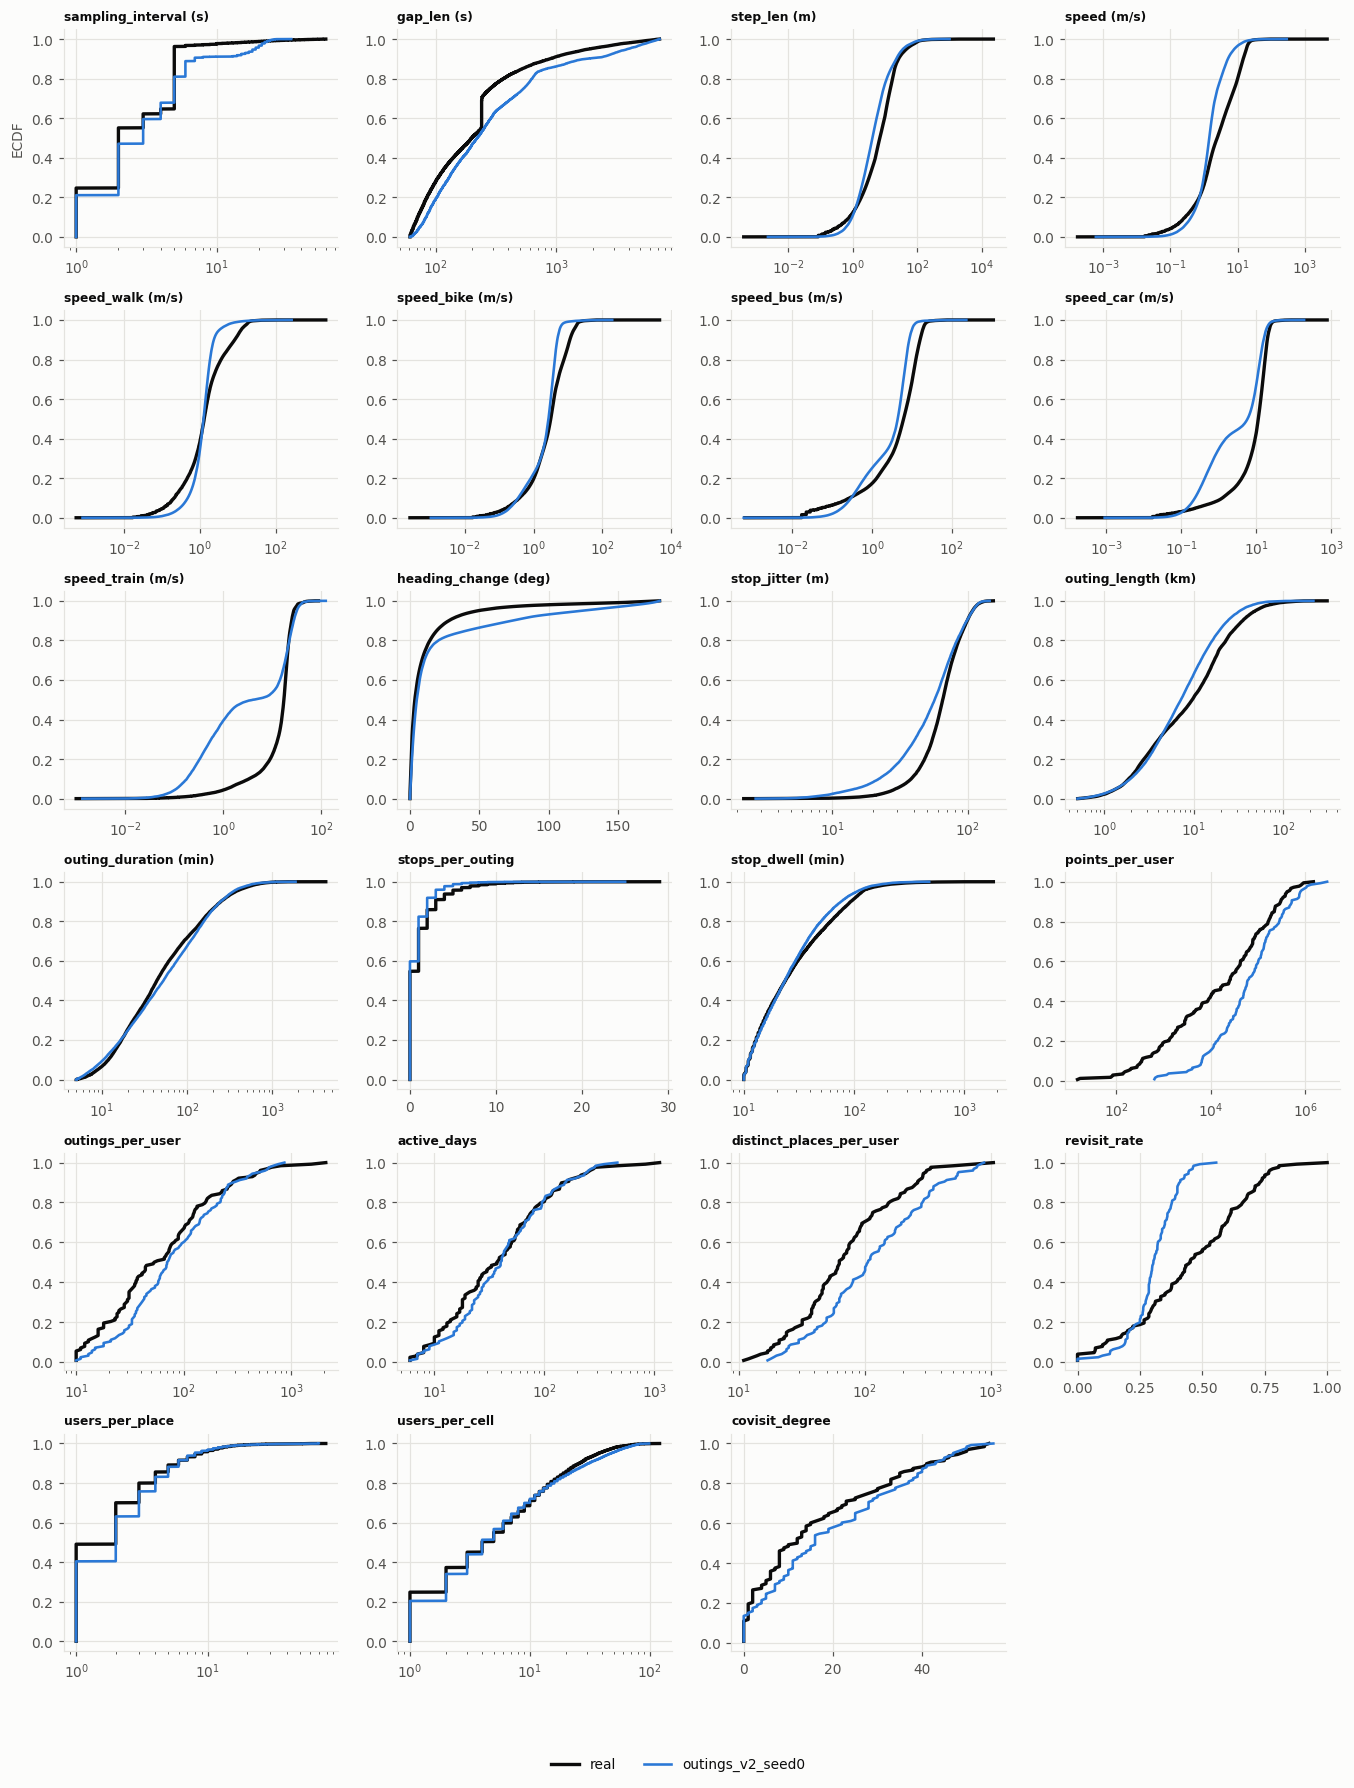

In [6]:
V.ecdf_panels(real, syns)

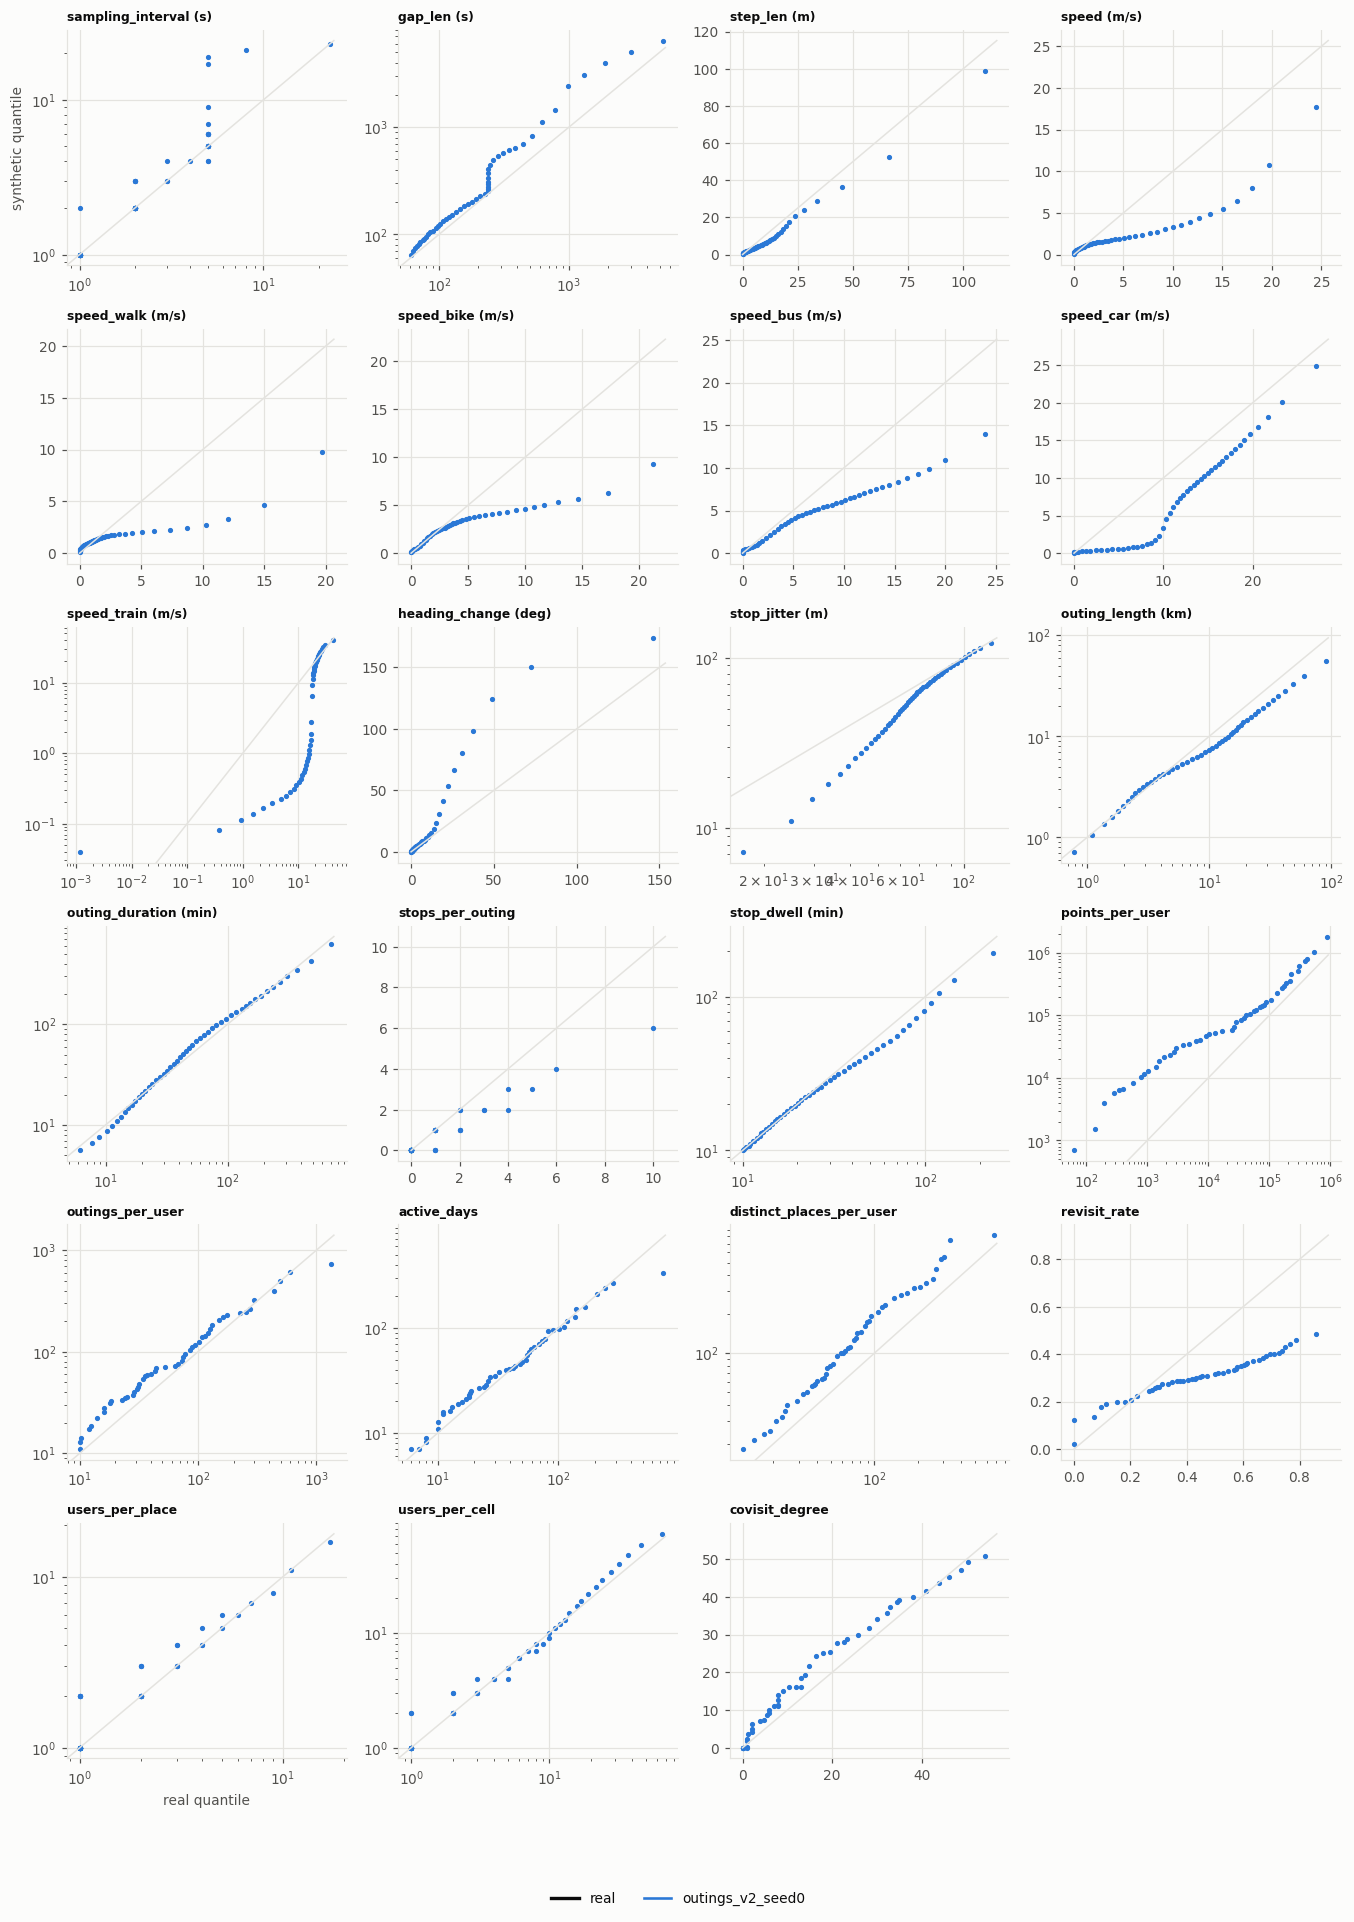

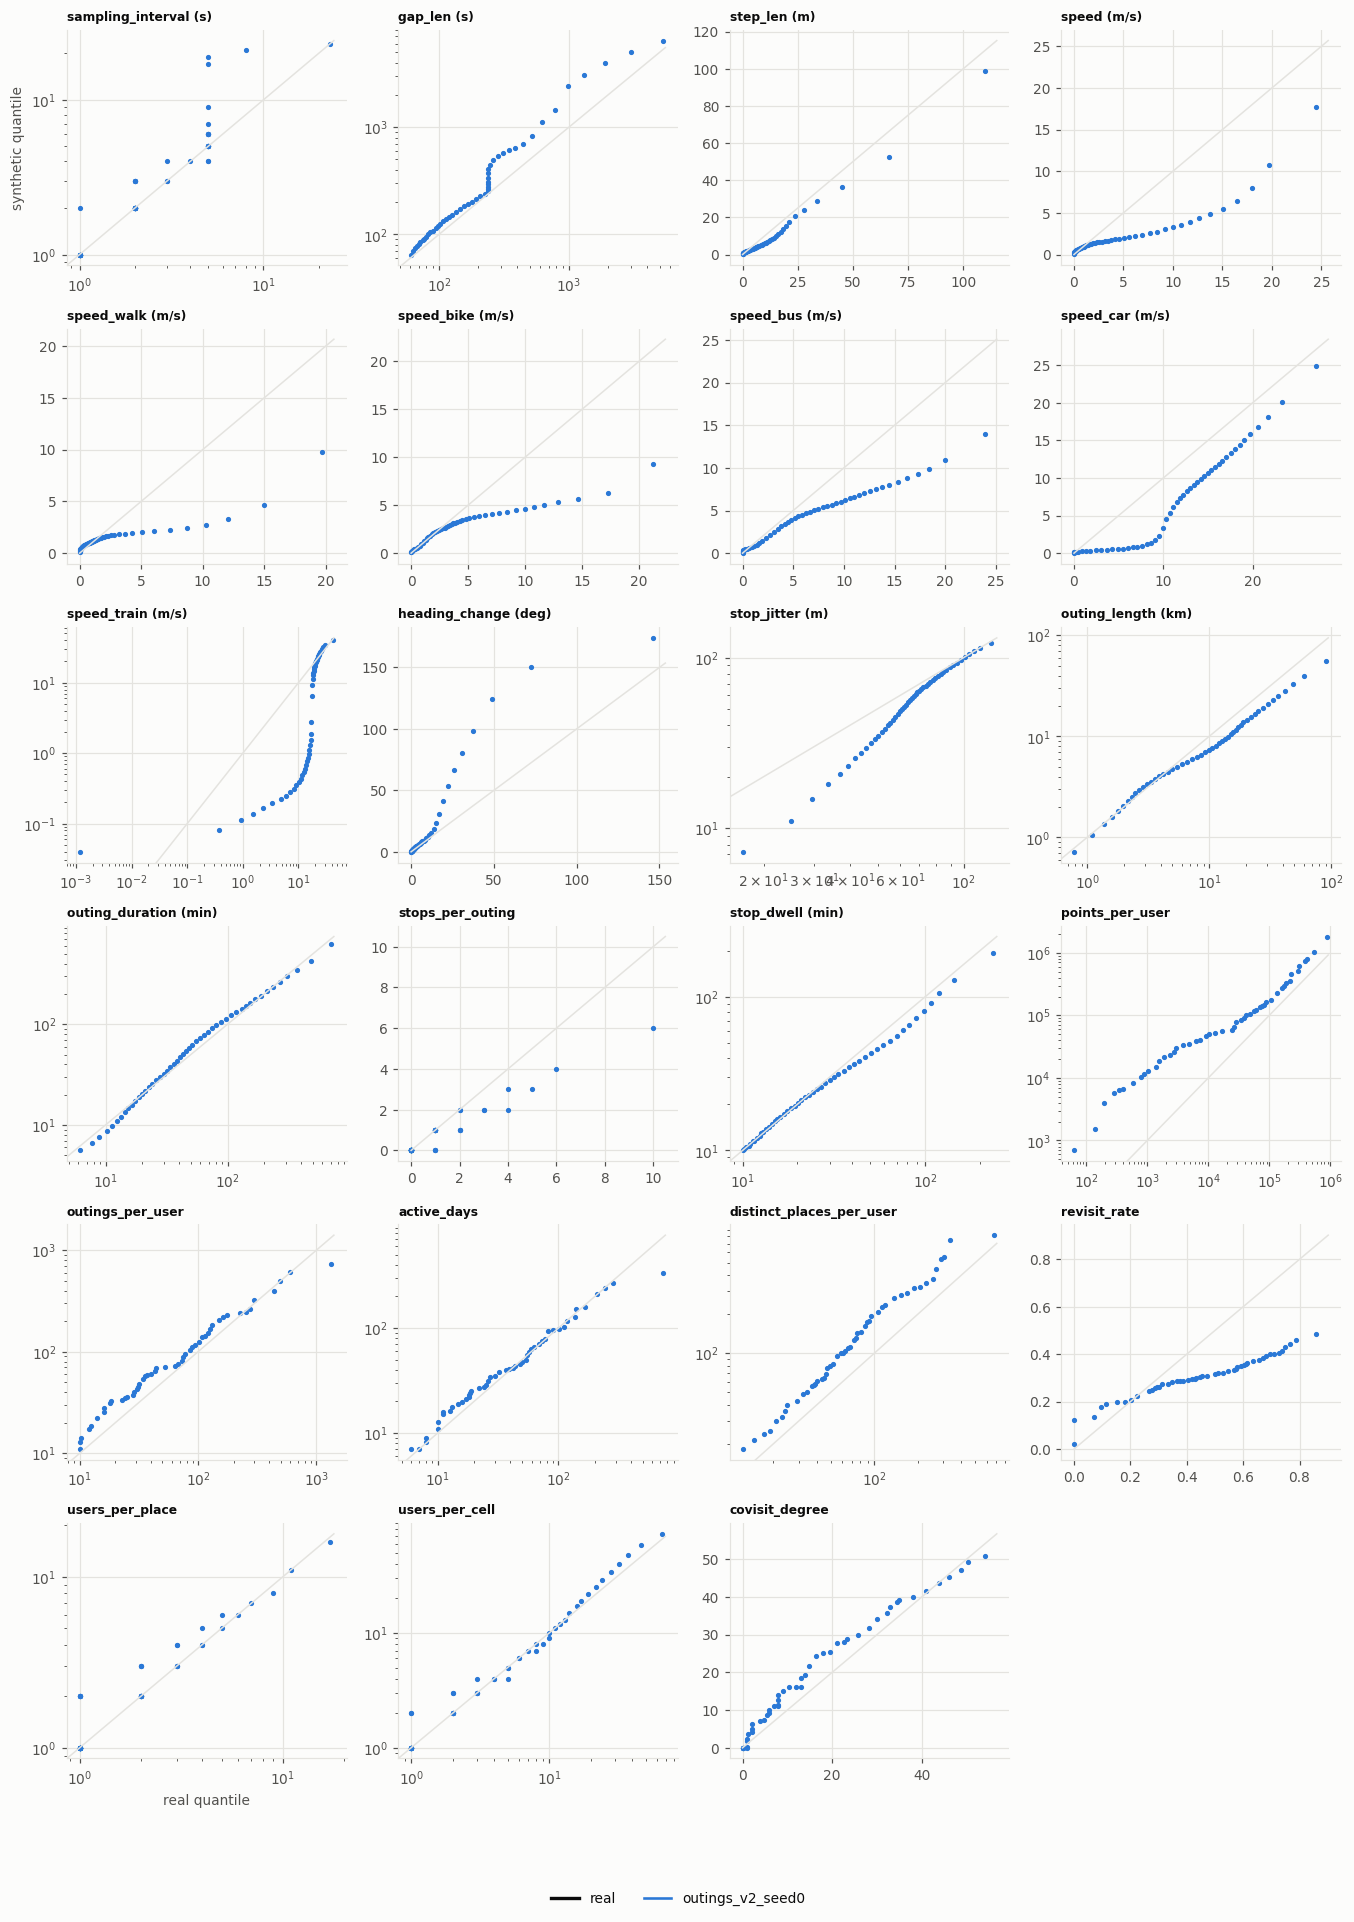

In [7]:
V.qq_panels(real, syns)

**What we see.** Most of the original sensor gaps are closed (KS, first baseline -> now): heading
change 0.79 -> 0.11, step length 0.40 -> 0.15, gap length 0.34 -> 0.17, walk speed 0.59 -> 0.17, stop
jitter 0.41 -> 0.19, outing length 0.37 -> 0.14, outing duration 0.24 -> 0.06, stop dwell 0.12 -> 0.06.
Still off: the sampling interval (KS 0.15; synthetic p50 3 s vs 2 s and a 10-20 s tail, p95 19 vs 5 s);
speeds are now too SLOW (mean 2.5 vs 5.1 m/s; car and train have a slow shoulder - seed 0's
`sensor_speed` is below its floor; speed is out of scope, realfake D11); points per user 2.0x (202k vs
102k); distinct places per user 1.7x; and the revisit rate is the largest remaining gap (mean 0.30 vs
0.45, KS 0.50 - the first baseline overshot at 0.57, now it undershoots).

## 3. Time

Hour-of-day profiles of outing starts and stops (weekday / weekend, local time) and the coarse time-bin
shares. *Look for:* the real 08h and 17-18h start peaks and the weekend skew of stops.

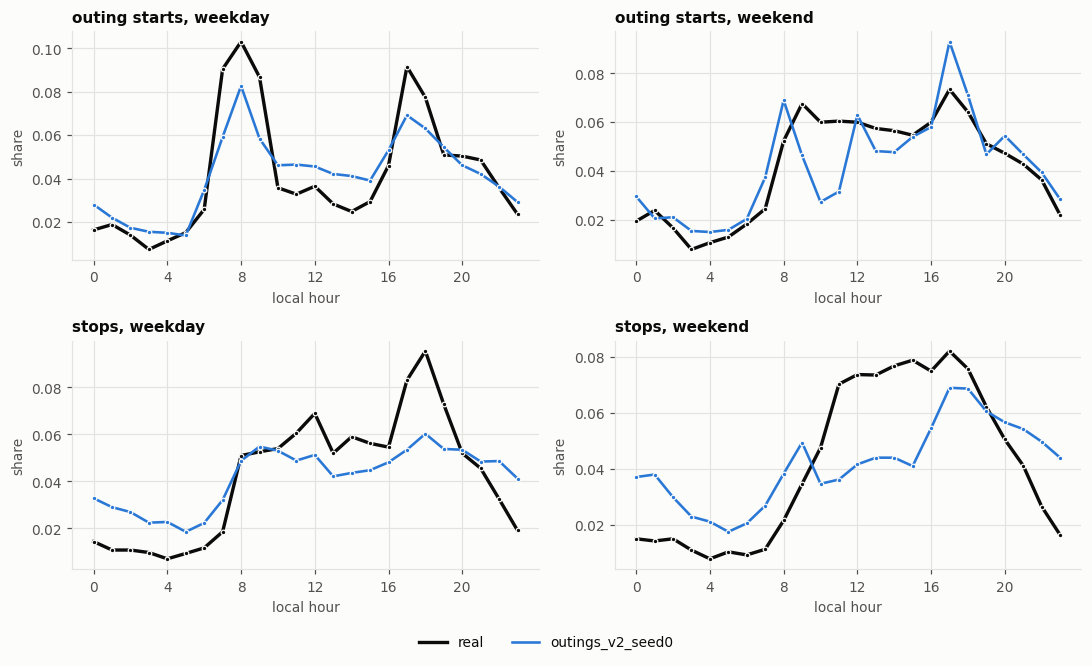

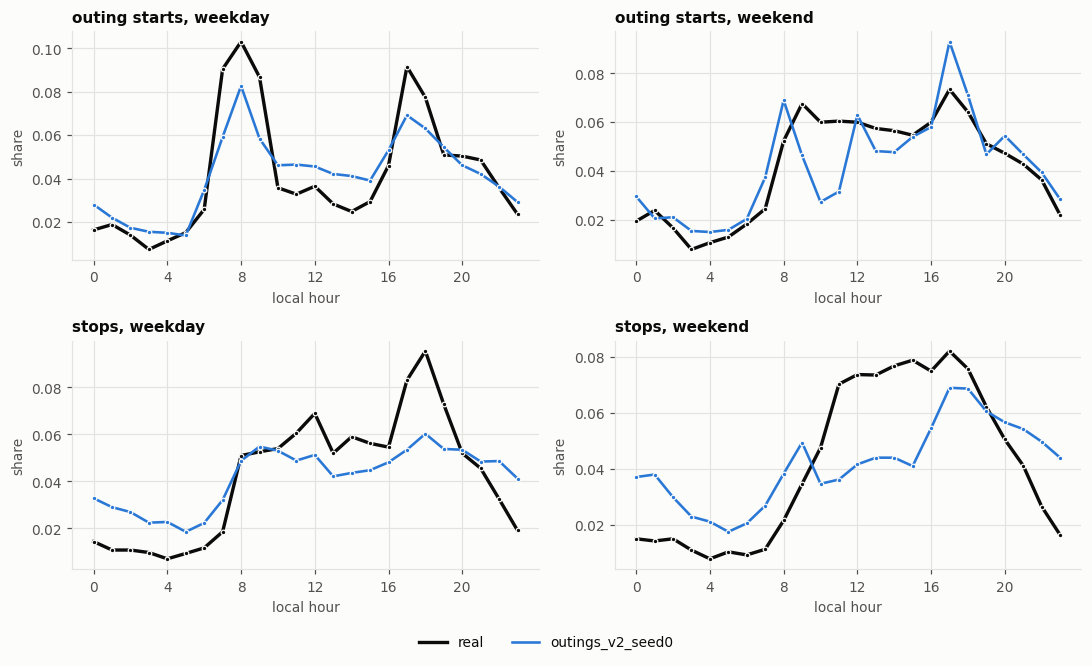

In [8]:
V.hour_profiles(real, syns)

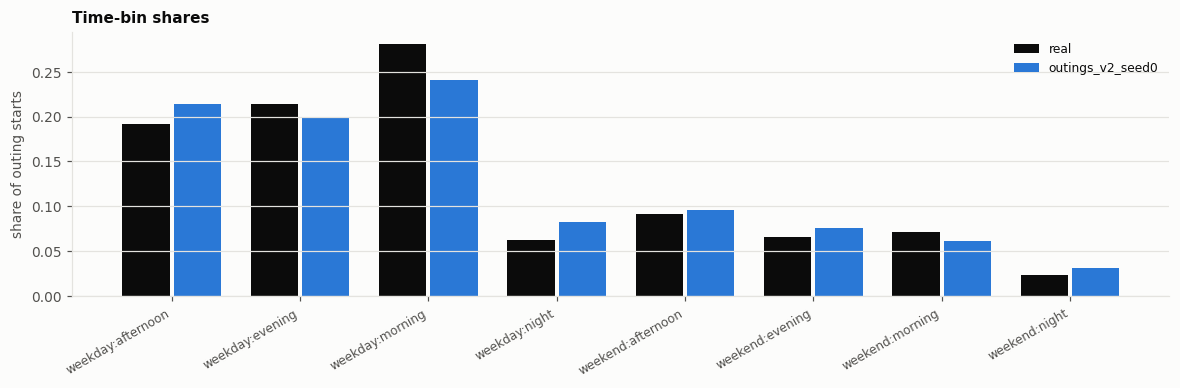

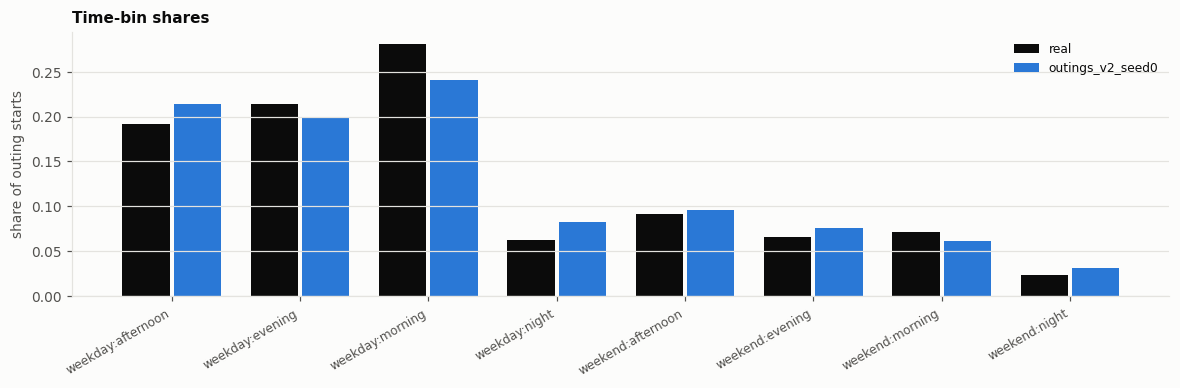

In [9]:
V.timebin_shares(real, syns)

**What we see.** The daily rhythm is much closer than at the first baseline: outing-start hour TV
0.13 weekday / 0.11 weekend (was 0.23 / 0.22), time-bin shares TV 0.06 (was 0.18). The weekday 08h and
17-18h start peaks are there but lower, with too many midday starts. Stops are the weaker part (TV 0.16
weekday / 0.22 weekend): synthetic stops leak into the night (0-6h shares 2-3x real) and miss the real
weekday 18h peak and the weekend 11-18h plateau.

## 4. Social / place structure

Users per place and per traversed cell (CCDF), revisit rate per user, and the co-visit degree
distribution; then the same panels on split halves of each dataset (A solid, B dashed) - a dataset whose
halves disagree is unstable before it is wrong. *Look for:* hub places reaching tens of users in the real
curve, and the synthetic co-visit degrees not exceeding the real ones.

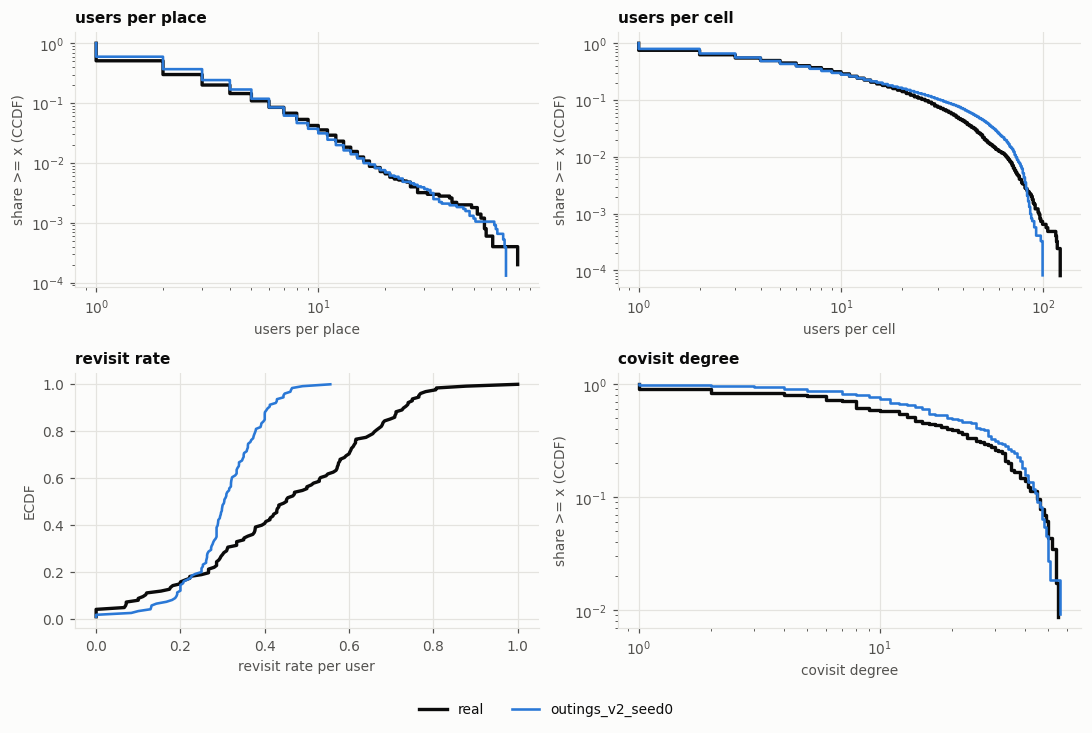

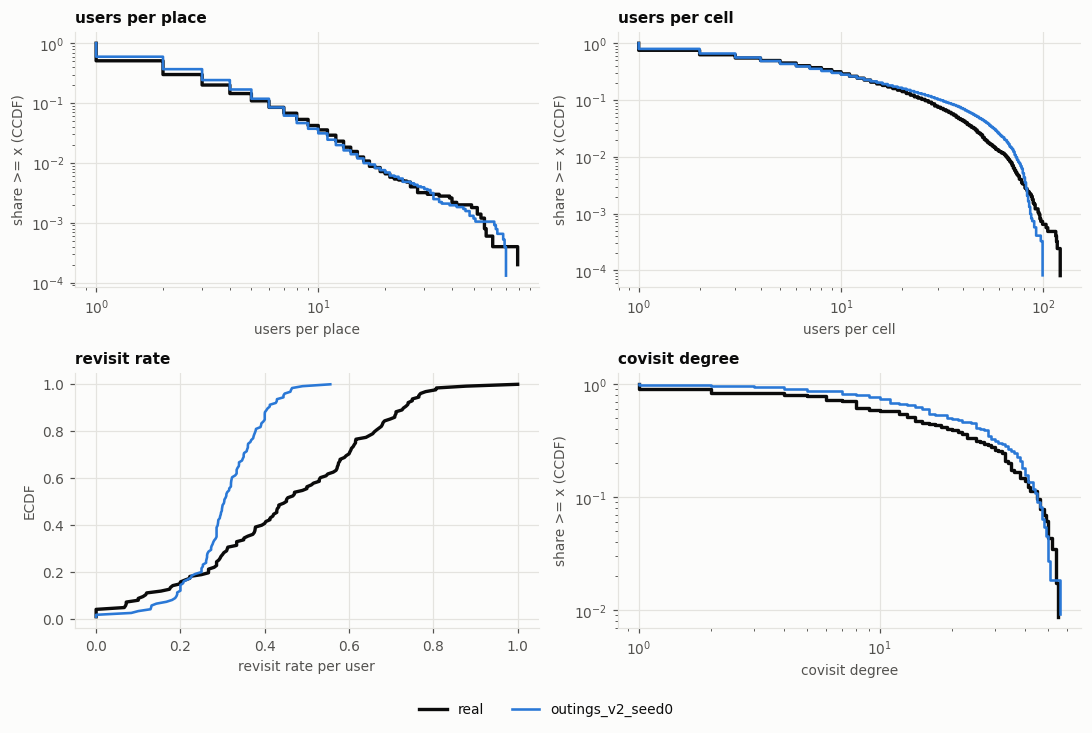

In [10]:
V.structure_panels(real, syns)

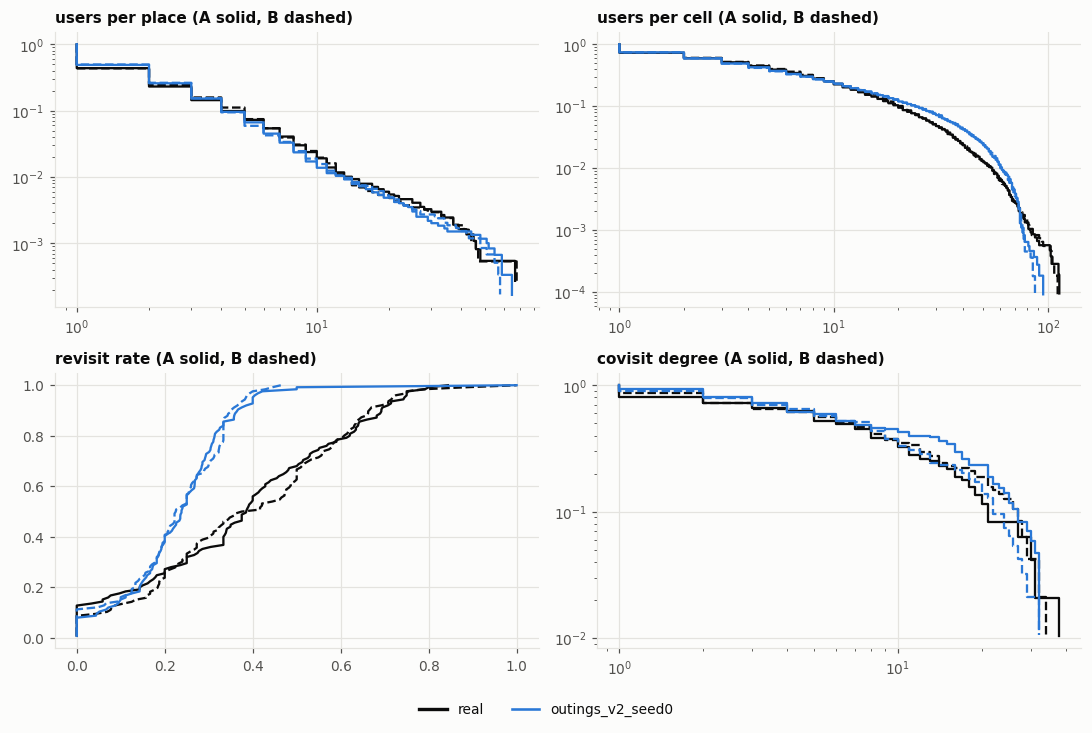

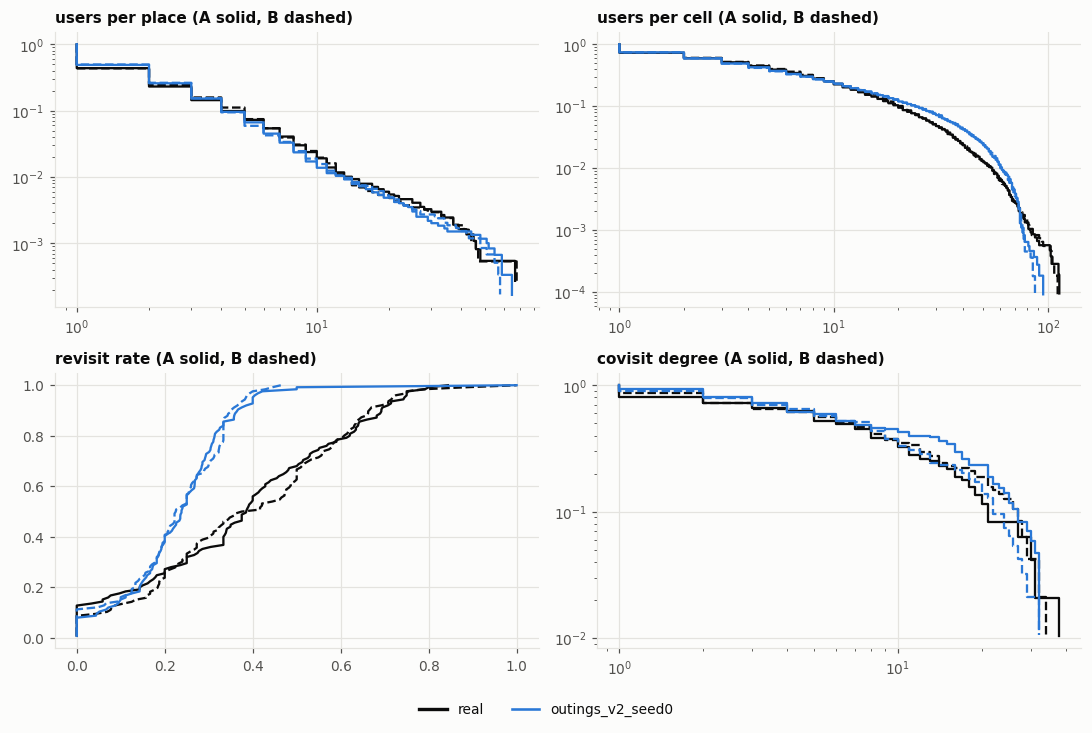

In [11]:
V.split_half_structure(real, syns)

**What we see.** Structure stays the closest part: users per place TV 0.09 with the same power-law
hub tail, users per cell KS 0.04, co-visit degree mean 19.5 vs 16.6 (KS 0.15). Revisit rate is the
outlier: every synthetic user sits between about 0.2 and 0.55, while real users spread from 0 to 1. The
split halves agree within each dataset (A solid, B dashed), so these gaps are real, not sampling noise.

## 5. Summary distance table

One row per quantity: moments of both sides (mean, std, skewness, kurtosis, p1..p99 in the CSV) and the
distances (KS, Wasserstein-1, total variation, relative error of moments). Written to
`geolife/eval/results/compare_<variant>.{csv,md}` so progress can be tracked run to run.

In [12]:
df = C.summary_table(real, syn)
C.write_summary(df, ROOT / "geolife" / "eval" / "results", f"compare_{Path(SYN).name}{TAG}")
df[[c for c in C.MD_COLS if c in df.columns]].round(4)

,quantity,group,n_real,n_syn,real_mean,syn_mean,real_p50,syn_p50,real_p95,syn_p95,ks,wasserstein,tv,rel_err_mean,rel_err_p50
0,sampling_interval,point,1948679,2143857,3.4333,4.4506,2.0000,3.0000,5.0000,19.0000,0.1530,1.3114,0.2662,0.2963,0.5000
1,gap_len,point,19095,8547,435.8478,687.4003,199.0000,221.0000,1881.6000,3920.1000,0.1735,251.5526,0.2480,0.5772,0.1106
2,step_len,point,1948679,2143857,13.2668,9.9970,6.4173,4.0834,45.1482,36.1333,0.1538,3.4804,0.2285,0.2465,0.3637
3,speed,point,1955426,2146200,5.0891,2.4864,2.1943,1.4264,18.0311,7.9752,0.2285,2.7032,0.3093,0.5114,0.3499
4,speed_walk,point,837742,1351762,2.7915,1.6455,1.2382,1.2559,12.0458,3.3052,0.1692,1.4484,0.3127,0.4105,0.0143
5,speed_bike,point,415517,399453,4.5886,2.8830,3.0242,2.7169,14.6325,5.6827,0.2134,1.8114,0.2855,0.3717,0.1016
6,speed_bus,point,280043,162230,7.0161,4.4767,5.6861,4.3937,18.4419,9.9116,0.2597,2.6032,0.3631,0.3619,0.2273
7,speed_car,point,221391,110929,10.7415,6.7585,10.9307,5.7823,21.7112,18.0756,0.2636,4.0046,0.3179,0.3708,0.4710
8,speed_train,point,27077,14194,15.9980,10.9691,17.2358,4.0447,27.4975,31.8291,0.3917,6.0885,0.4420,0.3143,0.7653
9,heading_change,point,993359,798463,11.6325,20.7746,3.5321,4.9378,49.0771,124.0508,0.1060,9.1593,0.1540,0.7859,0.3980
